# Predicting Citi Bike traffic: three non-HMM approaches

**Dennis Hantman · UCSD CSE 250A — Probabilistic Reasoning and Learning**

How much can an observed morning tell us about bicycle traffic later that day? We compare three models on the same Upper East Side ↔ Midtown trip counts:

1. **Historical hourly averages:** predict a typical weekday or weekend.
2. **Activity-adjusted averages:** scale that typical profile using this morning's traffic.
3. **A multivariate Gaussian:** use relationships between hours and directions to condition on the morning.

Our task is to forecast **hours 12–23 from observations through 11:59 AM**. The notebook progresses from each model's intuition and assumptions to its equations, implementation, examples, and held-out results. No HMM is implemented.


In [1]:
%matplotlib inline
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from IPython.display import display

DATA, REFERENCE, OUTPUT = Path("data"), Path("reference"), Path("outputs")
CUTOFF = 12
COLORS = {"Historical average": "#3568a5", "Activity-adjusted average": "#d37a26", "Gaussian": "#438b66"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)


No event loop hook running.


## 1. Data: two geographic proxies, two directions

We reuse the processed **2019 NYC Citi Bike** dataset: 250,508 cross-zone trips across 363 days. Zone A is an Upper East Side **residential proxy**; Zone B is a Midtown **commercial proxy**. Their frozen registry contains 52 and 48 stations, selected using January–August data only. Exact geographic bounds and station/filter rules are in the README and supplied data files.

Each observation is a trip count by **local departure hour**, with directions A→B and B→A. All rider categories are included. Zero-count hours remain zero; the two daylight-saving transition dates are excluded so that every day has 24 hours. The labels describe geography, not individual riders' purposes.

We keep the original chronological split: **January–August training**, **September–October validation**, and **November–December test**.


In [2]:
frame = pd.read_csv(DATA / "daily_features.csv", parse_dates=["date"])
features = [f"{direction}_{h:02d}" for direction in ("AB", "BA") for h in range(24)]
X = frame[features].to_numpy(dtype=float)  # All 24 AB counts, then all 24 BA counts.
flows = np.stack([X[:, :24], X[:, 24:]], axis=-1)  # (days, hours, directions)
weekend = frame["is_weekend"].to_numpy(dtype=int)
train = frame["split"].eq("train").to_numpy()
validation = frame["split"].eq("validation").to_numpy()
test = frame["split"].eq("test").to_numpy()

display(frame.assign(daily_trips=X.sum(axis=1)).groupby("split", sort=False).agg(
    days=("date", "size"), first_date=("date", "min"), last_date=("date", "max"),
    mean_daily_trips=("daily_trips", "mean")))


,days,first_date,last_date,mean_daily_trips
split,,,,
train,242,2019-01-01,2019-08-31,715.756
validation,61,2019-09-01,2019-10-31,833.984
test,60,2019-11-01,2019-12-31,440.367


### What does a typical day look like?

Training weekdays show strong directional peaks at different times; weekends have a broader daytime profile. These are commuting-like aggregate patterns, but counts alone do not establish travel purpose. Any more elaborate model should first be compared with these simple calendar patterns.


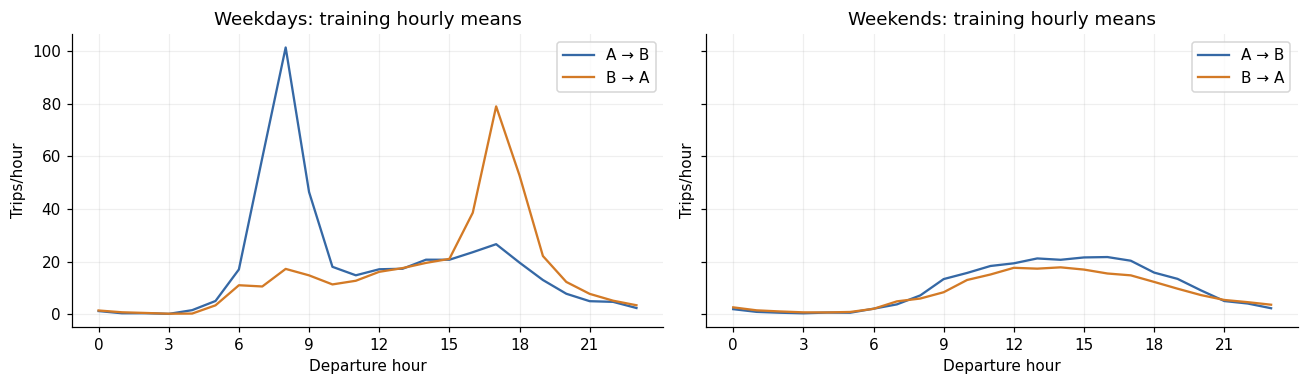

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for group, title, ax in zip([0, 1], ["Weekdays", "Weekends"], axes):
    typical = flows[train & (weekend == group)].mean(axis=0)
    ax.plot(range(24), typical[:, 0], label="A → B", color="#3568a5")
    ax.plot(range(24), typical[:, 1], label="B → A", color="#d37a26")
    ax.set(title=f"{title}: training hourly means", xlabel="Departure hour", ylabel="Trips/hour")
    ax.set_xticks(range(0, 24, 3)); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## 2. The common forecasting task

Represent day $d$ by the 48-dimensional vector

$$x_d=(AB_0,\ldots,AB_{23},BA_0,\ldots,BA_{23})^\top.$$

At noon, observe both directions for hours 0–11 and predict both for hours 12–23. A forecast is issued once: we do **not** update it with actual afternoon counts. Every model sees the same morning and weekday/weekend label, and is fitted using training data only.

The Gaussian keeps its **original validation-selected configuration**: separate weekday/weekend distributions and shrinkage $\alpha=0.5$. We do not select a new model using test performance. Both historical approaches use the same full-training means; the activity adjustment is the original fixed, unshrunk baseline.

**Timing caveat:** this reproduces our original retrospective benchmark using finalized departure-hour OD counts. A morning departure's destination may become known after noon. Thus this is not a claim that all such counts would be available to a live system by 11:59. The separate completion-available next-hour study is retained outside this notebook.

For the following examples, we use the same typical validation weekday and weekend, chosen near each group's median traffic level rather than by model error.


In [4]:
hourly_means = np.stack([flows[train & (weekend == g)].mean(axis=0) for g in [0, 1]])
daily_totals = X.sum(axis=1)
example_days = []
for g in [0, 1]:
    candidates = np.flatnonzero(validation & (weekend == g))
    totals = daily_totals[candidates]
    example_days.append(candidates[np.argmin(np.abs(totals - np.median(totals)))])

# One shared plotting function keeps each model section focused on its forecast.
def plot_examples(predict, name):
    fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
    for row, day in enumerate(example_days):
        forecast = predict(flows[day:day+1, :CUTOFF], weekend[day:day+1])[0]
        for direction, ax in enumerate(axes[row]):
            ax.plot(range(24), flows[day, :, direction], color="#444444", label="Actual")
            ax.plot(range(CUTOFF, 24), forecast[:, direction], color=COLORS[name], label=name)
            ax.axvspan(0, 11.5, color="gray", alpha=.1)
            ax.axvline(11.5, color="gray", linestyle="--", linewidth=1)
            day_type = "weekend" if weekend[day] else "weekday"
            ax.set(title=f"{frame.date.iloc[day].date()} ({day_type}), {['A → B', 'B → A'][direction]}",
                   xlabel="Departure hour", ylabel="Trips/hour", xticks=range(0, 24, 3))
            ax.grid(alpha=.15)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: shaded morning is observed; colored line is the afternoon forecast")
    plt.tight_layout(); plt.show()


## 3. Historical hourly average baseline

**Intuition:** use the typical hourly pattern for this kind of day. For weekday/weekend group $g$, hour $h$, and direction $r$,

$$\mu_{g,h,r}=\frac{1}{n_g}\sum_{d\in\mathcal T_g}y_{d,h,r},
\qquad \widehat y_{d,h,r}=\mu_{g(d),h,r},\quad h\ge12.$$

This estimates a calendar-dependent expected count without specifying a full count distribution. It captures average shape and directional asymmetry, but assumes that the expected profile is stable within each category. A quiet morning cannot lower its afternoon forecast.


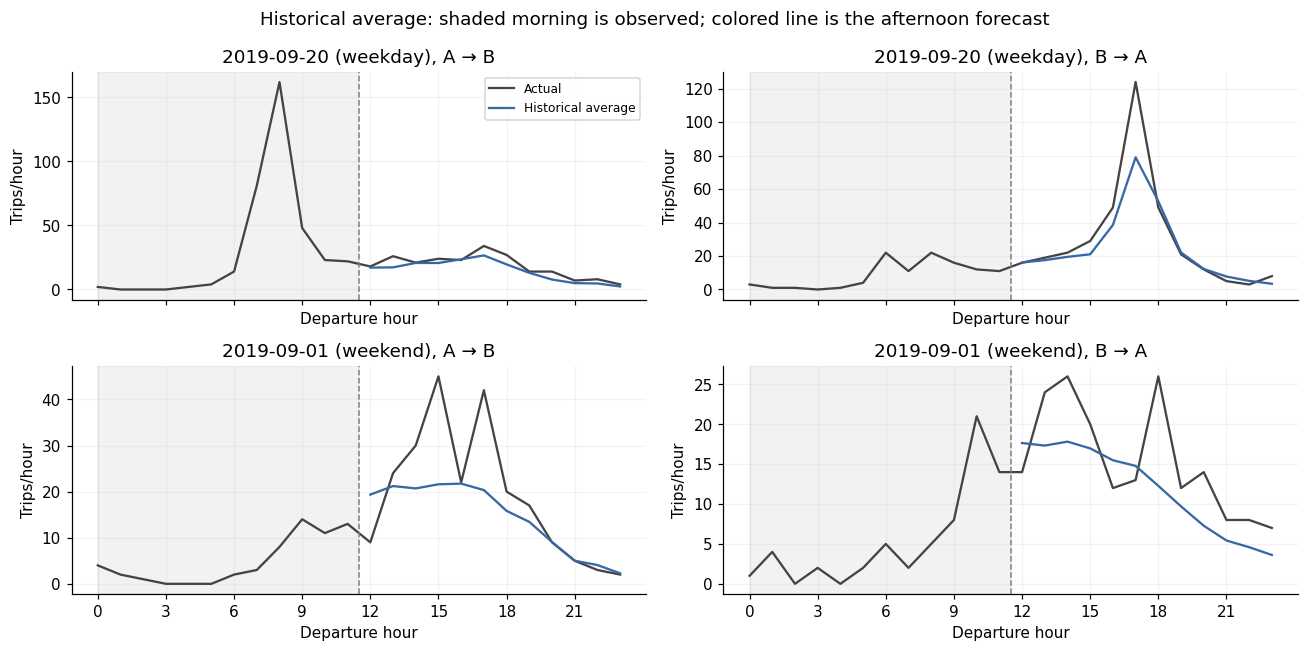

In [5]:
def historical_forecast(prefix, groups):
    cutoff = prefix.shape[1]
    return hourly_means[np.asarray(groups), cutoff:].copy()

plot_examples(historical_forecast, "Historical average")


## 4. Activity-adjusted historical average baseline

**Intuition:** keep the historical shape, but ask whether this morning has been busier or quieter than usual. Estimate one activity multiplier from both directions together:

$$s_d=\frac{\sum_{h<12}\sum_r y_{d,h,r}}
              {\sum_{h<12}\sum_r\mu_{g(d),h,r}},
\qquad \widehat y_{d,h,r}=s_d\mu_{g(d),h,r},\quad h\ge12.$$

If morning traffic is 60% of its historical expectation, predict 60% of the usual afternoon profile. This assumes a common multiplicative day-level effect carries from morning into afternoon. It preserves the historical ratios between future hours and directions; it cannot predict a new afternoon disruption or a direction-specific change.

We retain the original **unshrunk ratio**. For a zero historical denominator, the implementation falls back to a multiplier of one.


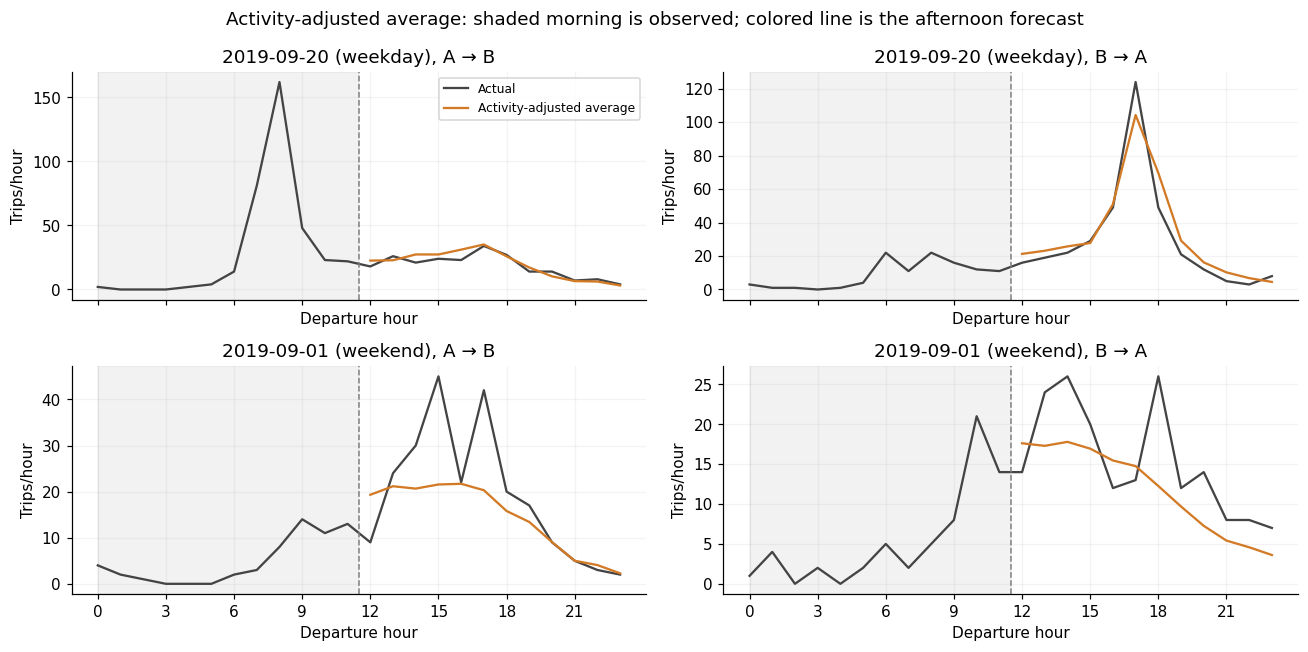

In [6]:
def activity_forecast(prefix, groups):
    expected = hourly_means[np.asarray(groups), :prefix.shape[1]].sum(axis=(1, 2))
    observed = prefix.sum(axis=(1, 2))
    scale = np.divide(observed, expected, out=np.ones(len(prefix)), where=expected > 0)
    return scale[:, None, None] * historical_forecast(prefix, groups)

plot_examples(activity_forecast, "Activity-adjusted average")


## 5. Multivariate Gaussian model

**Intuition:** a morning pattern can contain more information than a single total. For example, variation in morning A→B traffic may be associated with variation in later B→A traffic. A covariance matrix lets each observed component influence different future components differently.

For each weekday/weekend category, model a complete day as

$$x_d\mid g(d)=g\sim\mathcal N(\mu_g,\Sigma_g).$$

Training days are treated as replicate draws within their category; hourly components within a day are **not assumed independent**. Estimate

$$\widehat\mu_g=\frac1{n_g}\sum_d x_d,\qquad
S_g=\frac1{n_g-1}\sum_d(x_d-\widehat\mu_g)(x_d-\widehat\mu_g)^\top.$$

To stabilize a 48-dimensional covariance, use the original regularization:

$$\widehat\Sigma_g=(1-\alpha)S_g+\alpha\operatorname{diag}(\operatorname{diag}(S_g))+\epsilon_g I,$$
$$\alpha=0.5,\qquad \epsilon_g=\max(10^{-6},10^{-6}\operatorname{tr}(S_g)/48).$$

Shrinkage reduces noisy cross-feature covariances; the ridge makes numerical solves well defined. The value of $\alpha$ is loaded from the existing validation decision, not chosen again here.


In [7]:
selection = json.loads((REFERENCE / "phase1_selection.json").read_text())
ALPHA = float(selection["selected_alpha"])

def fit_gaussian(training_vectors, alpha):
    mean = training_vectors.mean(axis=0)
    sample_cov = np.cov(training_vectors, rowvar=False, ddof=1)
    ridge = max(1e-6, 1e-6 * np.trace(sample_cov) / 48)
    covariance = ((1 - alpha) * sample_cov
                  + alpha * np.diag(np.diag(sample_cov))
                  + ridge * np.eye(48))
    return mean, covariance

gaussians = {g: fit_gaussian(X[train & (weekend == g)], ALPHA) for g in [0, 1]}
print(f"Fitted weekday and weekend Gaussians with the frozen shrinkage alpha = {ALPHA}.")


Fitted weekday and weekend Gaussians with the frozen shrinkage alpha = 0.5.


### Conditional inference: use the morning to predict the afternoon

Partition the mean and covariance into observed morning components $O$ and future components $F$. The conditional distribution is

$$x_F\mid x_O\sim\mathcal N(m_{F\mid O},C_{F\mid O}),$$
$$m_{F\mid O}=\mu_F+\Sigma_{FO}\Sigma_{OO}^{-1}(x_O-\mu_O),$$
$$C_{F\mid O}=\Sigma_{FF}-\Sigma_{FO}\Sigma_{OO}^{-1}\Sigma_{OF}.$$

The correction to $\mu_F$ depends on how the morning differs from its mean and how those deviations relate to the afternoon. Unlike the activity baseline, different future hours and directions can receive different adjustments.

The code uses a **Cholesky solve**, not an explicit inverse. It takes only the observed prefix as input. We retain conditional variances as well as means; the comparison uses the means, clipped at zero and kept continuous rather than rounded.


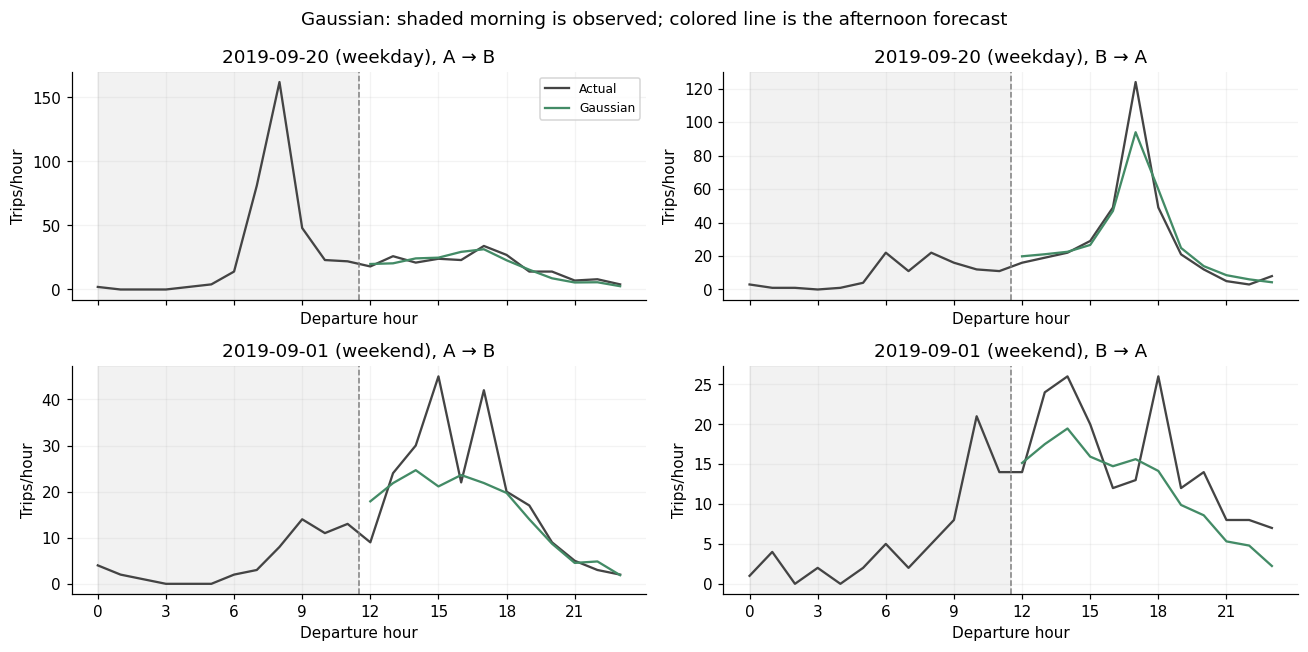

In [8]:
def gaussian_conditional(prefix, groups):
    cutoff = prefix.shape[1]
    observed = np.r_[np.arange(cutoff), np.arange(24, 24 + cutoff)]
    future = np.setdiff1d(np.arange(48), observed)
    values = np.concatenate([prefix[:, :, 0], prefix[:, :, 1]], axis=1)
    means = np.empty((len(prefix), len(future)))
    variances = np.empty_like(means)
    for group in np.unique(groups):
        rows = np.flatnonzero(groups == group)
        mu, cov = gaussians[int(group)]
        factor = cho_factor(cov[np.ix_(observed, observed)], lower=True)
        cross_cov = cov[np.ix_(future, observed)]
        gain = cho_solve(factor, cross_cov.T).T
        means[rows] = mu[future] + (values[rows] - mu[observed]) @ gain.T
        conditional_cov = cov[np.ix_(future, future)] - gain @ cross_cov.T
        variances[rows] = np.maximum(np.diag(conditional_cov), 0)
    shape = (len(prefix), 2, 24 - cutoff)
    return means.reshape(shape).transpose(0, 2, 1), variances.reshape(shape).transpose(0, 2, 1)


def gaussian_forecast(prefix, groups):
    mean, _ = gaussian_conditional(prefix, groups)
    return np.maximum(mean, 0)



plot_examples(gaussian_forecast, "Gaussian")


### Reading the covariance structure

These training-fitted correlation matrices are the covariance matrices normalized by each feature's standard deviation. The two diagonal blocks describe relationships within a direction; the off-diagonal blocks describe relationships across directions and hours. The divider marks the boundary between the 24 AB features and the 24 BA features.

Correlations can reflect common daily activity or seasonality as well as directional patterns. They are predictive associations, not evidence of travel purpose or causality.


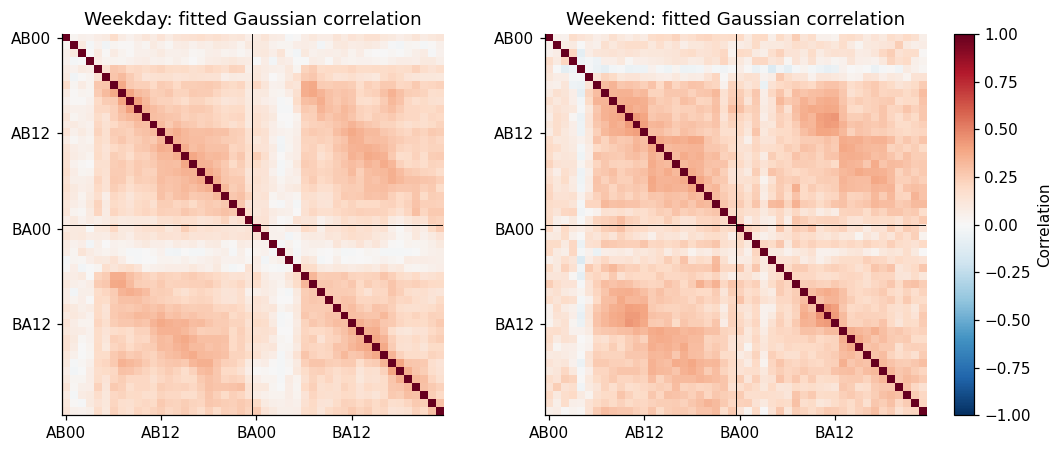

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for g, ax in enumerate(axes):
    cov = gaussians[g][1]
    sd = np.sqrt(np.diag(cov))
    correlation = cov / np.outer(sd, sd)
    image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.axvline(23.5, color="black", linewidth=.6); ax.axhline(23.5, color="black", linewidth=.6)
    ax.set_xticks([0, 12, 24, 36], ["AB00", "AB12", "BA00", "BA12"])
    ax.set_yticks([0, 12, 24, 36], ["AB00", "AB12", "BA00", "BA12"])
    ax.set_title(f"{['Weekday', 'Weekend'][g]}: fitted Gaussian correlation")
fig.colorbar(image, ax=axes, fraction=.025, pad=.03, label="Correlation")
plt.show()


## 6. Evaluation on identical future hours

Every model predicts the same 12 hours in both directions. There are **1,440 test target cells**: 60 days × 12 hours × two directions. Observed morning counts are excluded from scoring.

$$\operatorname{MAE}=\frac1N\sum_i|\widehat y_i-y_i|,\qquad
\operatorname{RMSE}=\sqrt{\frac1N\sum_i(\widehat y_i-y_i)^2}.$$

We pool errors over all target cells before taking the RMSE square root. The validation results describe the already fixed models; the test results are held-out outcomes, not an opportunity to change parameters.


In [10]:
models = {"Historical average": historical_forecast,
          "Activity-adjusted average": activity_forecast,
          "Gaussian": gaussian_forecast}
predictions, rows = {}, []
for split, mask in [("validation", validation), ("test", test)]:
    actual = flows[mask, CUTOFF:]
    for name, predict in models.items():
        forecast = predict(flows[mask, :CUTOFF], weekend[mask])
        predictions[(split, name)] = forecast
        residual = forecast - actual
        rows.append({"model": name, "split": split,
                     "MAE": np.abs(residual).mean(), "RMSE": np.sqrt(np.mean(residual**2))})
results = pd.DataFrame(rows)
display(results.pivot(index="model", columns="split", values=["MAE", "RMSE"]).reindex(models).round(3))
OUTPUT.mkdir(exist_ok=True)
results.to_csv(OUTPUT / "noon_summary.csv", index=False)


MAE               RMSE           
split                       test validation    test validation
model                                                         
Historical average         8.656      7.040  12.916     11.188
Activity-adjusted average  3.867      6.059   6.210      9.576
Gaussian                   4.565      5.957   6.843      9.486

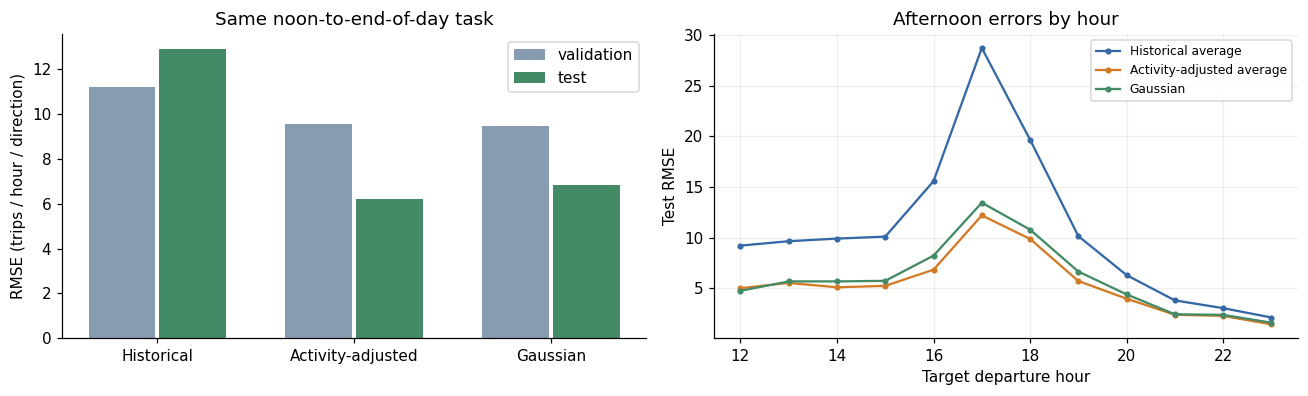

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for split, shift, color in [("validation", -.18, "#879cb1"), ("test", .18, "#438b66")]:
    values = results.loc[results["split"].eq(split)].set_index("model").reindex(models)["RMSE"]
    axes[0].bar(np.arange(3) + shift, values, width=.34, color=color, label=split)
axes[0].set_xticks(range(3), ["Historical", "Activity-adjusted", "Gaussian"])
axes[0].set(ylabel="RMSE (trips / hour / direction)", title="Same noon-to-end-of-day task")
axes[0].legend()
for name in models:
    residual = predictions[("test", name)] - flows[test, CUTOFF:]
    axes[1].plot(range(CUTOFF, 24), np.sqrt(np.mean(residual**2, axis=(0, 2))),
                 marker="o", markersize=3, color=COLORS[name], label=name)
axes[1].set(xlabel="Target departure hour", ylabel="Test RMSE", title="Afternoon errors by hour")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()


## 7. Why does activity adjustment outperform the Gaussian here?

The reproduced test RMSEs are **12.916** for static averages, **6.210** for activity adjustment, and **6.843** for the Gaussian. The Gaussian is much better than a static profile, but its extra flexibility does not beat the single activity multiplier on this test.

The test period is quieter than training: approximately **440 versus 716 trips/day**. To see how the models adapt to that shift, compare their predicted total afternoon traffic with what actually occurred. This table is a descriptive error diagnostic; it does not change any model.


In [12]:
actual_total = flows[test, CUTOFF:].sum(axis=(1, 2)).mean()
calibration = pd.DataFrame([
    {"model": name, "predicted_afternoon_per_day": predictions[("test", name)].sum(axis=(1, 2)).mean()}
    for name in models])
calibration["actual_afternoon_per_day"] = actual_total
calibration["mean_total_error"] = calibration["predicted_afternoon_per_day"] - actual_total
display(calibration.round(1))
calibration.to_csv(OUTPUT / "afternoon_calibration.csv", index=False)


,model,predicted_afternoon_per_day,actual_afternoon_per_day,mean_total_error
0,Historical average,429.5,254.5,175.0
1,Activity-adjusted average,273.4,254.5,18.9
2,Gaussian,315.7,254.5,61.2


The average observed test morning is about **62% of its historical expectation**. Applying this level adjustment lowers the average afternoon prediction from 429 trips to **273**, close to the actual **255**. The Gaussian also adapts, but its mean afternoon prediction remains higher, at **316**. Its remaining overprediction helps explain its larger error.

The models encode different adjustments. Activity scaling explicitly applies the same proportional reduction to every future component. The Gaussian instead makes a linear correction determined by the January–August cross-covariances, while retaining its training mean as a reference. Shrinkage stabilizes those estimates but attenuates cross-hour relationships. That structure need not transfer as well to quieter winter days as a direct scale adjustment.

This is evidence for the usefulness of day-level adaptation **in this benchmark**, not proof that shrinkage alone caused the difference or that activity adjustment is always superior. We do not retune the Gaussian after seeing the test results.


## 8. What each model captures—and misses

| Model | What it captures | Main limitation |
|---|---|---|
| Historical average | Typical weekday/weekend shapes and directional asymmetry | Cannot react to the current day or seasonal level shifts. |
| Activity-adjusted average | The typical shape plus one shared day-level multiplier | Assumes morning and afternoon scale together; preserves historical directional ratios. |
| Multivariate Gaussian | Hour- and direction-specific linear conditional relationships | Relies on stable training means/covariances and a continuous Gaussian approximation. |

A Gaussian assigns probability to negative and fractional counts; clipping its conditional mean is a forecast rule, not a nonnegative-count likelihood. The days are treated as replicate observations within each group even though seasonality and serial dependence remain. There are only 68 training weekend days, so covariance regularization is important.

All three models predict recorded trips, not latent demand or station availability. Geographic labels and correlation patterns do not identify why individuals ride. These 2019 test months have also been examined in earlier project phases, so the findings are exploratory rather than a fresh confirmatory study.


## 9. Takeaway for the group project

A useful baseline should explain both **the usual hourly pattern** and **how active today has been**. The Gaussian adds finer covariance-based conditioning, but the simpler proportional adjustment performs better on this test. A more elaborate model should therefore demonstrate useful information beyond these effects.

For a fair HMM comparison, use the same panel, chronological splits, available morning observations, and AB/BA afternoon targets. The README gives the input files and notes the differences from the teammate notebook's current 2024 setup. Exact preprocessing and previous next-hour results remain available outside the main narrative.
